# Python codes for replicating Figure 1

In [7]:
import bioalpha
import scanpy as sc
import pandas as pd
import numpy as np
import os
import re
import anndata as ad
import pandas as pd
import random
import math
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA
import matplotlib.pyplot as plt
import seaborn as sns
import scipy.io as sio
import platform
import subprocess
import sys

In [5]:
import warnings
warnings.simplefilter(action='ignore', category=FutureWarning)
exec(open('/data/CEM/smacklab/team_scratch/wyang114/scripts/utils/_figure_options.py').read())
plt.rcParams['pdf.fonttype'] = 42
plt.rcParams['font.family'] = 'sans-serif'
np.random.seed(2023)

In [8]:
print(f"Python Version: {platform.python_version()}")
print(f"Python Executable: {sys.executable}\n")
print("--- Installed Packages ---")

# Runs pip list using the active kernel's Python executable
result = subprocess.run([sys.executable, "-m", "pip", "list"], capture_output=True, text=True)
print(result.stdout)

Python Version: 3.11.10
Python Executable: /packages/envs/bioalpha-0.13.0-cuda-12/bin/python

--- Installed Packages ---
Package                   Version
------------------------- -----------
anndata                   0.9.2
asttokens                 2.4.1
attrs                     24.2.0
bioalpha-cu12             0.13.1
certifi                   2024.8.30
charset-normalizer        3.4.0
comm                      0.2.2
contourpy                 1.3.0
ctxcore                   0.2.0
cycler                    0.12.1
cytoolz                   1.0.0
debugpy                   1.8.7
decorator                 5.1.1
exceptiongroup            1.2.2
executing                 2.1.0
fastjsonschema            2.20.0
fonttools                 4.54.1
frozendict                2.4.6
GEOparse                  2.0.4
gseapy                    1.1.3
h5py                      3.12.1
idna                      3.10
importlib_metadata        8.5.0
ipykernel                 6.29.5
ipython                   8.2

## Panel 1: age and sex distribution of the 55 individual macaques

In [6]:
info = pd.read_csv('/scratch/nsnyderm/u01/intermediate_files/cell-class_h5ad_update/all_regions_obs.csv')

/tmp/ipykernel_1232982/3209429545.py:1: DtypeWarning: Columns (15,22) have mixed types. Specify dtype option on import or set low_memory=False.
  info = pd.read_csv('/scratch/nsnyderm/u01/intermediate_files/cell-class_h5ad_update/all_regions_obs.csv')


In [9]:
df = info.groupby(['animal_id', 'sex', 'social_group', 'age']).size().reset_index(name='count')

In [11]:
df.to_csv('/scratch/wyang114/outputs/all_region_sample_info.csv',index=False)

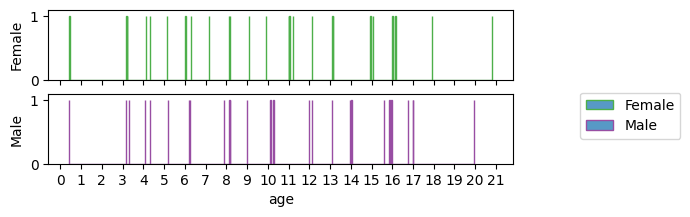

In [15]:
import pandas as pd
import matplotlib.pyplot as plt
import collections
import seaborn as sns

df = pd.read_csv('/scratch/wyang114/outputs/all_region_sample_info.csv')
df_sample = df.groupby(['age','sex','social_group','animal_id']).size().to_frame('count').reset_index()
df_sample = df_sample[df_sample['count']>0]
df_sample.loc[df_sample['animal_id']=='43N','age']=16.99
df_sample.loc[df_sample['animal_id']=='3D1','age']=13.12

sample_count = collections.Counter(df_sample['sex'])
fig,axes = plt.subplots(figsize=(6,2),ncols=1, nrows=2,sharex=True,sharey=True)
binsize = 0.01
axes[0] = sns.histplot(data = df_sample[df_sample['sex']=='F'],x='age',#bins=30,
                       ax=axes[0],binwidth=binsize,
                       edgecolor=sex_colors[0],label='Female',linewidth=1)
axes[0].set_ylabel('Female')
axes[0].set_ylim([0,1.1])
axes[0].set_xticks(np.arange(0, 22, 1.0))
#axes[0].set_yticks([0,2,4])

axes[1] = sns.histplot(data = df_sample[df_sample['sex']=='M'],x='age',#bins=30,
                       ax=axes[1],binwidth=binsize,
                       edgecolor=sex_colors[1],label='Male',linewidth=1)
axes[1].set_ylabel('Male')
axes[1].set_ylim([0,1.1])
axes[1].set_xticks(np.arange(0, 22, 1.0))
#axes[1].set_yticks([0,1,2])
fig.legend(['Female', 'Male'], bbox_to_anchor=(1, 0.5),loc = 'upper left')
plt.savefig(f'/scratch/wyang114/figures/1_paper_figures/1_fig1/animal_age_bin{binsize}_adjusted.pdf',bbox_inches='tight',format='pdf')

## panel2 and 4: all regions umap

In [3]:
adata_all = sc.read_h5ad('/scratch/nsnyderm/u01/intermediate_files/cell-class_h5ad_update/all_regions.h5ad')
cell_id = adata_all.obs_names.tolist()
random.shuffle(cell_id)
select_id = cell_id[:round(adata_all.shape[0]/10)]
subset = adata_all[select_id,:]
subset.write_h5ad('/scratch/nsnyderm/u01/intermediate_files/cell-class_h5ad_update/all_regions_500k.h5ad')

In [8]:
WORK_PATH = '/scratch/nsnyderm/u01/intermediate_files/cell-class_h5ad_update/'
subset = sc.read_h5ad(os.path.join(WORK_PATH,'all_regions_500k.h5ad'))
select_genes = subset.var.index[np.where(~subset.var['chr'].isin(['X','Y']))]
subset = subset[:,select_genes]
sc.pp.normalize_total(subset, target_sum=1e4)
sc.pp.log1p(subset)
sc.pp.highly_variable_genes(subset, n_top_genes=10000) #hvg
subset = subset[:, subset.var.highly_variable]
sc.pp.regress_out(subset, keys='n_umi',n_jobs=20) #bioalpha requires hvg<5000 for this step
sc.pp.scale(subset, max_value=10) #bioalpha might generate memory-intensive output at this step (400G for 500k)
sc.tl.pca(subset, n_comps=50)
sc.pp.neighbors(subset, n_neighbors=30, n_pcs=30) #n_neighbors=30, n_pcs=30
sc.tl.umap(subset,min_dist=0.3,spread=1.0,n_components=2) #min_dist=0.25,spread=1.0

#subset.write_h5ad('/scratch/nsnyderm/u01/intermediate_files/cell-class_h5ad_update/all_regions_500k_processed.h5ad')
#pd.DataFrame(subset.obsm['X_pca']).to_csv(os.path.join(WORK_PATH, 'adata_500k_scale.pca.csv'))
#sio.mmwrite('/scratch/nsnyderm/u01/intermediate_files/cell-class_h5ad_update/all_regions_500k_pca.mtx',subset.obsm['X_pca'])

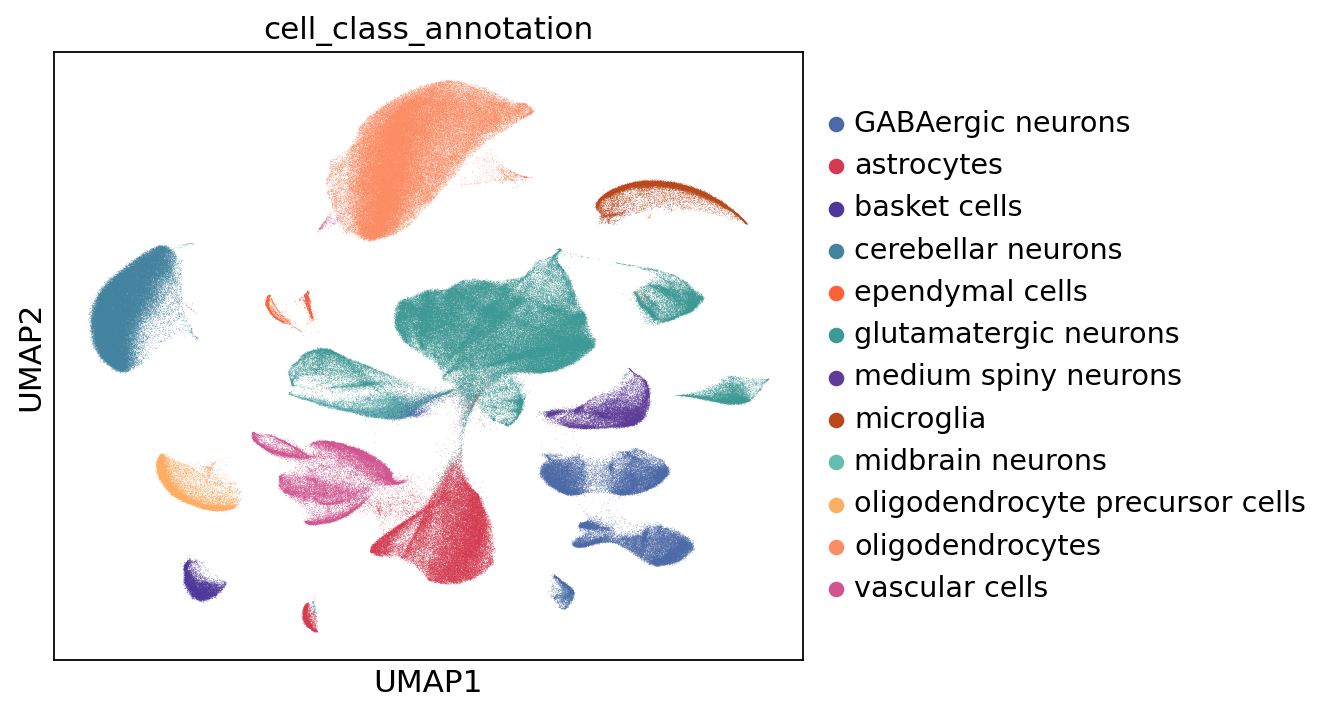

In [31]:
#subset = sc.read_h5ad('/scratch/nsnyderm/u01/intermediate_files/cell-class_h5ad_update/all_regions_500k_processed.h5ad')
valid_categories = subset.obs['cell_class_annotation'].unique()
category_colors = {
    name: value for name, value in color_dict.items()
    if name in valid_categories
}
cats = subset.obs['cell_class_annotation'].cat.categories
subset.uns['cell_class_annotation_colors'] = [category_colors[c] for c in cats]
sc.set_figure_params(vector_friendly=True, dpi_save=300,figsize=(6,5)) 
fig = sc.pl.umap(subset, color='cell_class_annotation', size=0.3,return_fig=True, show=False,sort_order=False)
fig.savefig("/scratch/wyang114/figures/1_paper_figures/1_fig1/umap_cellclass_rasterized_size0.3.pdf", dpi=300, bbox_inches='tight')

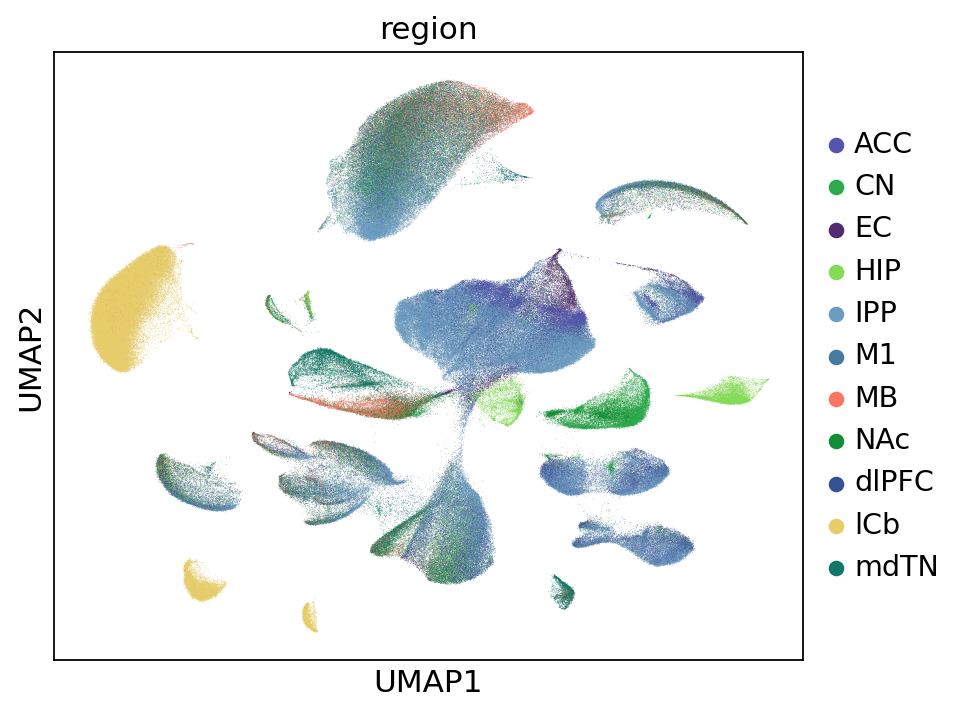

In [36]:
# valid_categories = subset.obs['region'].unique()
# category_colors = {
#     name: value for name, value in color_dict.items()
#     if name in valid_categories
# }
# cats = subset.obs['region'].cat.categories
# subset.uns['region_colors'] = [category_colors[c] for c in cats]
# sc.set_figure_params(vector_friendly=True, dpi_save=300,figsize=(6,5))
# subset = subset[np.random.permutation(subset.n_obs), :].copy()
fig = sc.pl.umap(subset, color='region', size=0.3,return_fig=True, show=False,sort_order=False)
fig.savefig("/scratch/wyang114/figures/1_paper_figures/1_fig1/umap_region_rasterized_size0.3.pdf", dpi=300, bbox_inches='tight')

In [18]:
adata_all = adata_all.raw.to_adata()
adata_all.write_h5ad('/scratch/wyang114/processed_data/merged_dataset/all_regions_500k.h5ad')

In [29]:
df_pca = pd.DataFrame(adata_all.obsm['X_pca'])
df_pca.columns = ['PC_'+ str(i) for i in range(1,51)]
df_pca.index = adata_all.obs_names.to_list()
df_pca.to_csv('/scratch/wyang114/processed_data/merged_dataset/all_regions_pca.csv')

## panel3: region-age group pca

In [4]:
#adata_all = sc.read_h5ad('/scratch/nsnyderm/u01/intermediate_files/cell-class_h5ad_update/all_regions.h5ad')
#bins = [0,3,6,21]
bins = [0,3,6,12,21]
covariate = 'region'
adata_all.obs['age_group'] = pd.cut(adata_all.obs['age'], bins, labels=['infants','adolescence','adult','aged'])
adata_all.obs['groups'] = adata_all.obs[covariate].astype('str')+'_'+adata_all.obs['age_group'].astype('str')
X=adata_all.raw.X
one_hot_sample = pd.get_dummies(adata_all.obs['groups']).values.astype(int)
pb_sample_mat = X.T.dot(one_hot_sample).T
print(pb_sample_mat.shape)
rowsum = pb_sample_mat.sum(axis=1)
pb_sample_mat_norm = np.log1p(pb_sample_mat/(rowsum.reshape(-1, 1)*1.0)*10000)
res_meta = pd.get_dummies(adata_all.obs['groups']).columns

(44, 29060)


In [63]:
pb_sample_mat_scaled = StandardScaler().fit_transform(pb_sample_mat_norm)
pca = PCA(n_components=3).fit_transform(pb_sample_mat_scaled)
mat = pca.T
data = {
    'PCA_1': mat[0],
    'PCA_2': mat[1],
    'PCA_3': mat[2],
     covariate: [name.split('_')[0] for name in res_meta],
    'age_group': [name.split('_')[1] for name in res_meta],
}
data =pd.DataFrame(data)
data['color']=data[covariate].map(color_dict)
#data.to_csv(f'./output/{ct}_pseudobulk_PC.csv')

In [64]:
pca = PCA(n_components=3)
pca.fit_transform(pb_sample_mat_scaled)
explained_variance = pca.explained_variance_ratio_

In [65]:
explained_variance

array([0.16404488, 0.14416566, 0.1098744 ])

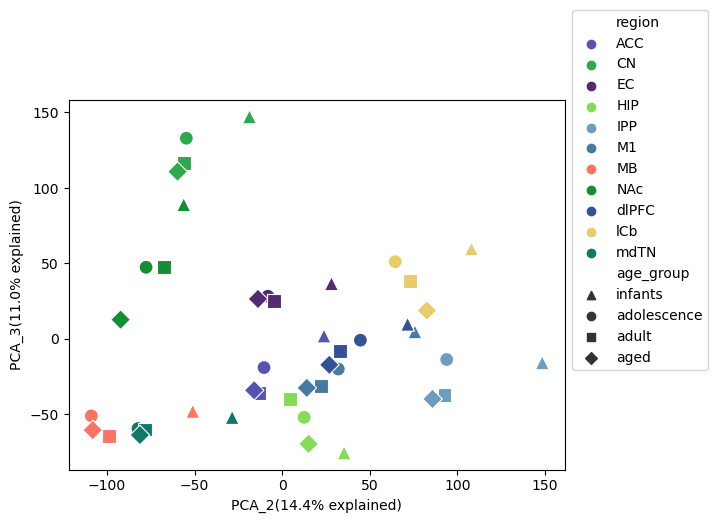

In [70]:
levels = ['infants','adolescence','adult','aged']
data['age_group']=pd.Categorical(data['age_group'], categories=levels, ordered=True)
regions = infant_subset[covariate].unique()
palette = dict(zip(unique_hues, pal['color'].values))
age_groups = data['age_group'].unique()
marker = dict(zip(levels, ['^','o','s','D']))
#sns.scatterplot(data = infant_subset, x="PCA_1", y="PCA_2",hue=covariate, palette = palette ,s=size,legend=None,marker='x')
sns.scatterplot(
    data=data,
    x="PCA_2",
    y="PCA_3",
    hue="region",  # Color based on this variable
    palette=palette,
    style="age_group",  # Shape based on this variable
    markers = marker,
    s=100  # Size of the markers
    
)
plt.xlabel('PCA_2(14.4% explained)')
plt.ylabel('PCA_3(11.0% explained)')
plt.legend(loc='lower left', bbox_to_anchor=(1, 0.25), ncol=1)
plt.savefig(f'/scratch/wyang114/figures/1_paper_figures/1_fig1/fig1c_pseudobulk_pca_{covariate}-age-v3-pc2_3.pdf',bbox_inches='tight')

In [11]:
#remove MB basket cells and HIP MSN
adata_all = sc.read_h5ad('/scratch/nsnyderm/u01/intermediate_files/cell-class_h5ad_update/all_regions.h5ad')
df = adata_all.obs
filtered_df = df[~(((df['region'] == 'MB') & (df['cell_class_annotation'] == 'basket cells')) |
                   ((df['region'] == 'HIP') & (df['cell_class_annotation'] == 'medium spiny neurons')))]
select_cells = filtered_df.index
adata_all = adata_all[select_cells,:]
adata_all.write_h5ad('/scratch/nsnyderm/u01/intermediate_files/cell-class_h5ad_update/all_regions.h5ad')
adata_all.obs.to_csv('/scratch/nsnyderm/u01/intermediate_files/cell-class_h5ad_update/all_regions_obs.csv')
df = adata_all.obs
df = pd.DataFrame({'count':df['cell_class_annotation'].value_counts(),'freq':df['cell_class_annotation'].value_counts(normalize=True)})
df.to_csv('/scratch/wyang114/outputs/cell-class_count.csv')

<Axes: xlabel='region', ylabel='spearman_correlation'>

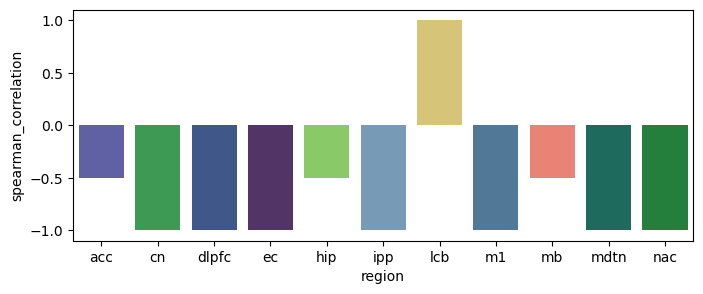

In [32]:
import seaborn as sns
df = pd.read_csv('./output/pseudobulk_PC.csv')
df['age_group'] = pd.Categorical(df['age_group'],categories=['young','adult','aged'],ordered=True)
df['age_group_code'] = df['age_group'].cat.codes
temp = pd.DataFrame(df.groupby('region').apply(lambda x: x['PCA_2'].corr(x['age_group_code'],method='spearman'))).rename(columns={0:'spearman_correlation'})
custom_palette = ['#5555b0','#2caa4d','#345296','#532b70','#84db55','#6c9cc0','#e6cd69','#467aa1','#fc7462','#117867','#148e34']
fig,ax = plt.subplots(1, 1, figsize=(8, 3))
sns.barplot(x='region', y='spearman_correlation', data=temp, hue='region',palette=custom_palette, ax=ax,)

## panel4: marker genes, subcluster counts and hierarchical clustering

In [4]:
ct_levels = ['glutamatergic neurons', 'GABAergic neurons','medium spiny neurons','cerebellar neurons',
            'basket cells','midbrain neurons','oligodendrocyte precursor cells',
            'oligodendrocytes','astrocytes','microglia','vascular cells','ependymal cells']
adata = sc.read_h5ad('/scratch/nsnyderm/u01/intermediate_files/cell-class_h5ad_update/all_regions_500k.h5ad')
df = pd.read_csv('/scratch/nsnyderm/u01/intermediate_files/cell-class_h5ad_update/all_regions_obs.csv')

processed_dir = '/scratch/nsnyderm/u01/intermediate_files/reclustered_cell_types_update/'
files = os.listdir(processed_dir)
files = [file for file in files if re.search(r'Res1',file)]
file = files[0]
adata.obs['ct_louvain']=''
prefix_dict = {'astrocytes':'ASTR','ependymal-cells':'EPEN','cortex':'CTN',
         'basal-ganglia':'BGN','cerebellum':'CRN','microglia':'MGL',
         'midbrain':'MBN','vascular-cells':'VASC','opc-olig':'OPC',
         'hippocampal':'HIP','thalamus':'THN'}
for file in files:
    temp = sc.read_h5ad(processed_dir+file)
    prefix = prefix_dict[file.split('_')[1]]
    adata.obs.loc[temp.obs_names,'ct_louvain']= [prefix+i for i in temp.obs['louvain']]
adata.write_h5ad('/scratch/nsnyderm/u01/intermediate_files/finalized_class_annotation/all_regions_processed.h5ad')

/tmp/ipykernel_4046904/691042455.py:36: UserWarning: No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.
  axes[1].legend().remove()


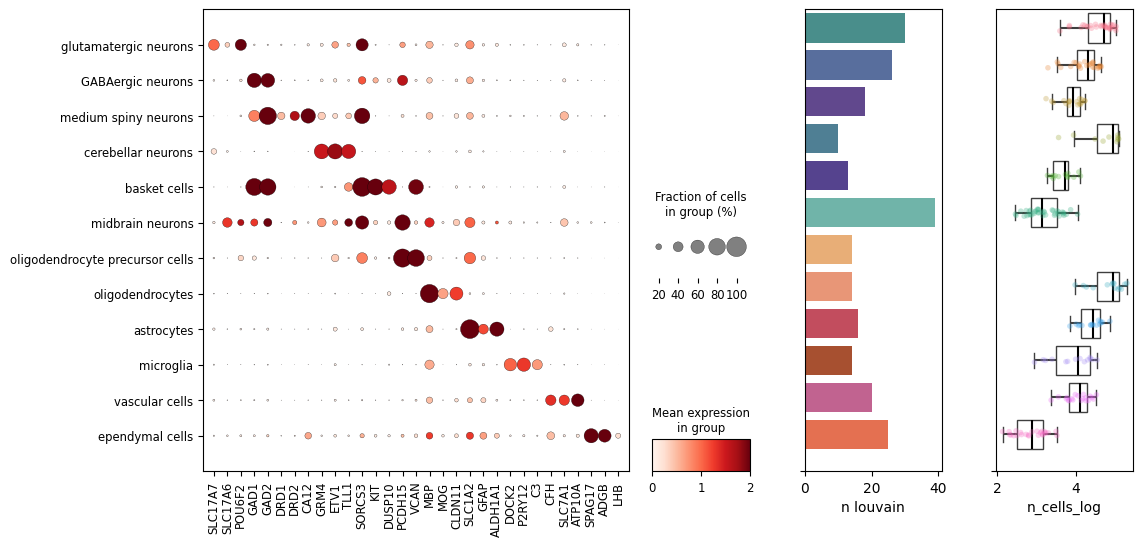

In [10]:
adata.raw = adata
sc.pp.normalize_total(adata, target_sum=1e4)
sc.pp.log1p(adata)
fig,axes = plt.subplots(figsize=(12,6),ncols=3, nrows=1,sharex=False,sharey=False,
                       gridspec_kw={'width_ratios': [8,2,2]})
marker_genes_dict = {'glutaminergic neurons': ['SLC17A7','SLC17A6','POU6F2'],
                     'GABAergic neurons': ['GAD1','GAD2'],
                     'medium spiny neurons':['DRD1','DRD2','CA12'],
                     'cerebellar neurons': ['GRM4','ETV1','TLL1'],
                     'basket cells': ['SORCS3','KIT','DUSP10'],
                     
                     'oligodendrocyte precursor cells': ['PCDH15','VCAN'],
                     'oligodendrocyte': ['MBP','MOG','CLDN11'],
                     'astrocyte': ['SLC1A2','GFAP','ALDH1A1'],
                     'microglia':['DOCK2','P2RY12','C3'],
                     'vascular cells':['CFH','SLC7A1','ATP10A'],
                     'ependymal cells':['SPAG17','ADGB','LHB'],
                    }
adata.obs['cell_class_annotation'] = adata.obs['cell_class_annotation'].cat.reorder_categories(ct_levels)
axes[0]=sc.pl.dotplot(adata, sum(marker_genes_dict.values(), []), groupby='cell_class_annotation',gene_symbols='external_gene_name',
                    cmap = 'Reds',figsize=[8,5],ax=axes[0],
                   use_raw=False, dendrogram=False, swap_axes=False,vmax=2,show=False)

df['cell_class_annotation']=pd.Categorical(df['cell_class_annotation'],categories=ct_levels,ordered=True)
distinct_counts = (df.groupby(['cell_class_annotation'])['louvain'].nunique().rename('n_louvain')).reset_index()
distinct_counts.index = distinct_counts['cell_class_annotation']
distinct_counts.loc['oligodendrocyte precursor cells','n_louvain']=14

ct_palette = distinct_counts.index.map(color_dict).tolist()
sns.barplot(data=distinct_counts, x="n_louvain", y="cell_class_annotation", 
            hue="cell_class_annotation",orient='h',
            palette=dict(zip(distinct_counts.index.tolist(),ct_palette)),ax=axes[1])
axes[1].set_xlabel('n louvain')
axes[1].set_ylabel('')
axes[1].set_yticks('')
axes[1].legend().remove()

df['group']=df['cell_class_annotation']
df.loc[df['cell_class_annotation']=='oligodendrocyte precursor cells','group']='oligodendrocytes'
count_df = df.value_counts(subset=['group', 'louvain']).reset_index(name='n_cells')
count_df['n_cells_log']=np.log10(count_df['n_cells'])
axes[2]=sns.boxplot(data=count_df, x='n_cells_log', y='group',
            boxprops={'facecolor': 'none'},showfliers=False,
            whiskerprops={'linewidth': 1.5},medianprops={'color': 'black', 'linewidth': 1.5},
                   ax=axes[2])
axes[2]=sns.stripplot(x="n_cells_log", y="group", data=count_df, jitter=True, alpha=0.3,
              hue='group', size=4,ax=axes[2])
axes[2].set_ylabel('')
axes[2].set_yticks('')

plt.savefig(f'/scratch/wyang114/figures/1_paper_figures/1_fig1/fig1G_cell_class_markers_update.pdf',bbox_inches='tight')

In [10]:
adata = sc.read_h5ad('/scratch/nsnyderm/u01/intermediate_files/cell-class_h5ad_update/all_regions_500k_processed.h5ad')
adata_all.raw = adata_all
bioalpha.sc.pp.normalize_total(adata_all, target_sum=1e4)
bioalpha.sc.pp.log1p(adata_all)
bioalpha.sc.pp.highly_variable_genes(adata_all, n_top_genes=1000) #hvg
adata_all = adata_all[:, adata_all.var.highly_variable]
bioalpha.sc.pp.scale(adata_all, max_value=10)
bioalpha.sc.tl.pca(adata_all, n_comps=50)
adata_all.obs['ct_louvain']=pd.Categorical(adata_all.obs['ct_louvain'])
sc.tl.dendrogram(adata, use_rep='X_pca',linkage_method='ward',groupby='ct_louvain')

In [88]:
##Pseudobulk genes by summing them up
X = adata_all.raw.X
one_hot_sample = pd.get_dummies(adata_all.obs['ct_louvain']).values.astype(int)
pb_sample_mat = X.T.dot(one_hot_sample).T
#Create a pseudobulk adata of louvain cell groups
pb_meta = pd.DataFrame(adata_all.obs.groupby('ct_louvain').size().rename('NCells')).reset_index()
pb_adata = ad.AnnData(pb_sample_mat,obs = pb_meta, var = adata_all.raw.var)
pb_adata.obs_names = pb_adata.obs['ct_louvain'].astype('str')
sc.pp.normalize_total(pb_adata, target_sum=1e4)
sc.pp.log1p(pb_adata)

/packages/apps/mamba/1.5.1/lib/python3.11/site-packages/anndata/_core/anndata.py:121: ImplicitModificationWarning: Transforming to str index.
  warnings.warn("Transforming to str index.", ImplicitModificationWarning)


In [4]:
pb_adata = sc.read_h5ad('/scratch/wyang114/processed_data/merged_dataset/pb_louvain_all_regions_500k_500hvg.h5ad')
pb_adata.obs_names = pb_adata.obs['ct_louvain'].astype('str')

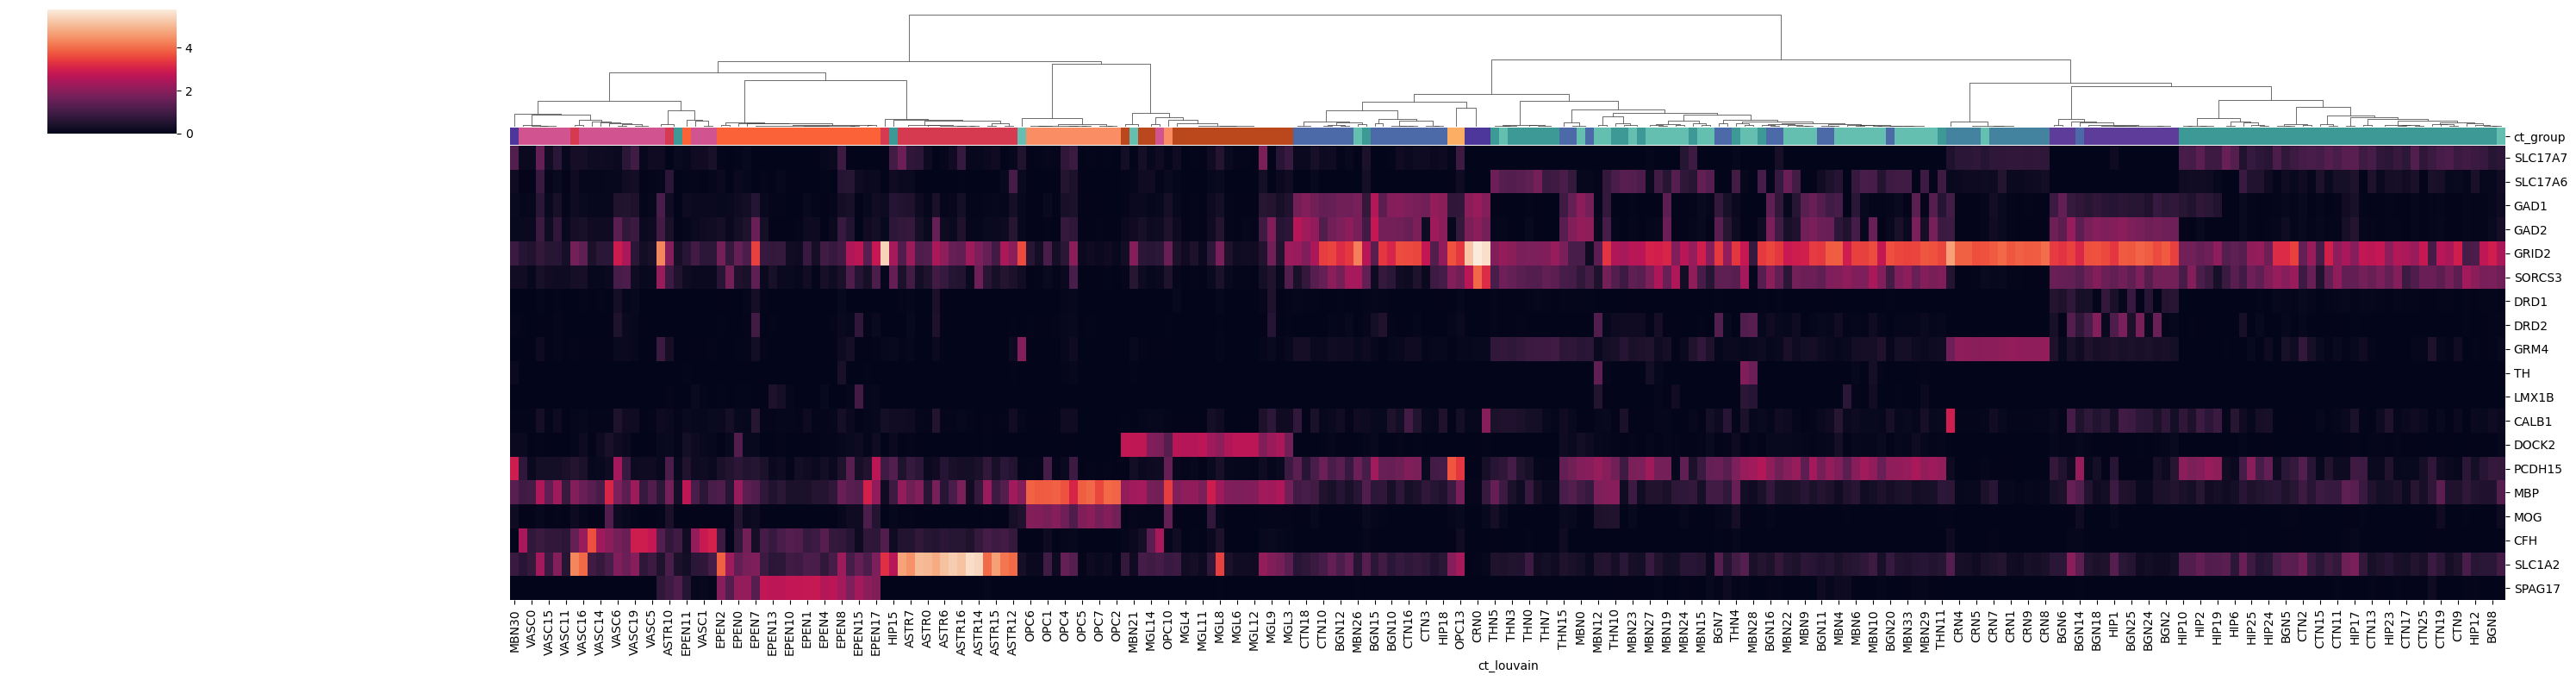

In [63]:
#expression
color_map = color_map.set_index('class')
pb_meta = pd.DataFrame(adata_all.obs.groupby('ct_louvain').size().rename('NCells')).reset_index()
temp = pd.DataFrame(adata_all.obs.groupby(['ct_louvain','cell_class_annotation']).size().unstack())

ct_group = temp.idxmax(axis=1)
pb_meta.index =pb_meta['ct_louvain'].astype('str')
pb_meta['ct_group']=ct_group  #ct_group is defined to be the majority cell class but later it should be the cell class
row_linkage = adata_all.uns['dendrogram_ct_louvain']['linkage']
ct_ordering = adata_all.uns['dendrogram_ct_louvain']['categories_ordered']
df = pb_meta.copy()

#add normalized pseudobulk gene expression
markers = ['SLC17A7','SLC17A6','GAD1','GAD2','SORCS3','DRD1','DRD2','GRM4',
           'TH','LMX1B','CALB1',
           'DOCK2','PCDH15','MBP','MOG','CFH','SLC1A2','SPAG17'
           ]
mat_df = pd.DataFrame(pb_adata.X)
mat_df.index = pb_adata.obs_names
mat_df.columns = pb_adata.var['external_gene_name']
mat_expr = mat_df.loc[:,markers]
df = df.join(mat_expr)

ct_group = df.pop('ct_group')
lut = color_map.loc[color_map.index.isin(pb_meta['ct_group'].unique()),].to_dict()
row_colors = ct_group.map(lut['color'])
g = sns.clustermap(df.drop(columns=['ct_louvain','NCells']).T, col_colors=row_colors, row_cluster=False,
                   col_linkage = row_linkage,figsize=(30,8))
g.savefig('figures/fig1f_gene_expr_heatmap.pdf',bbox_inches='tight')

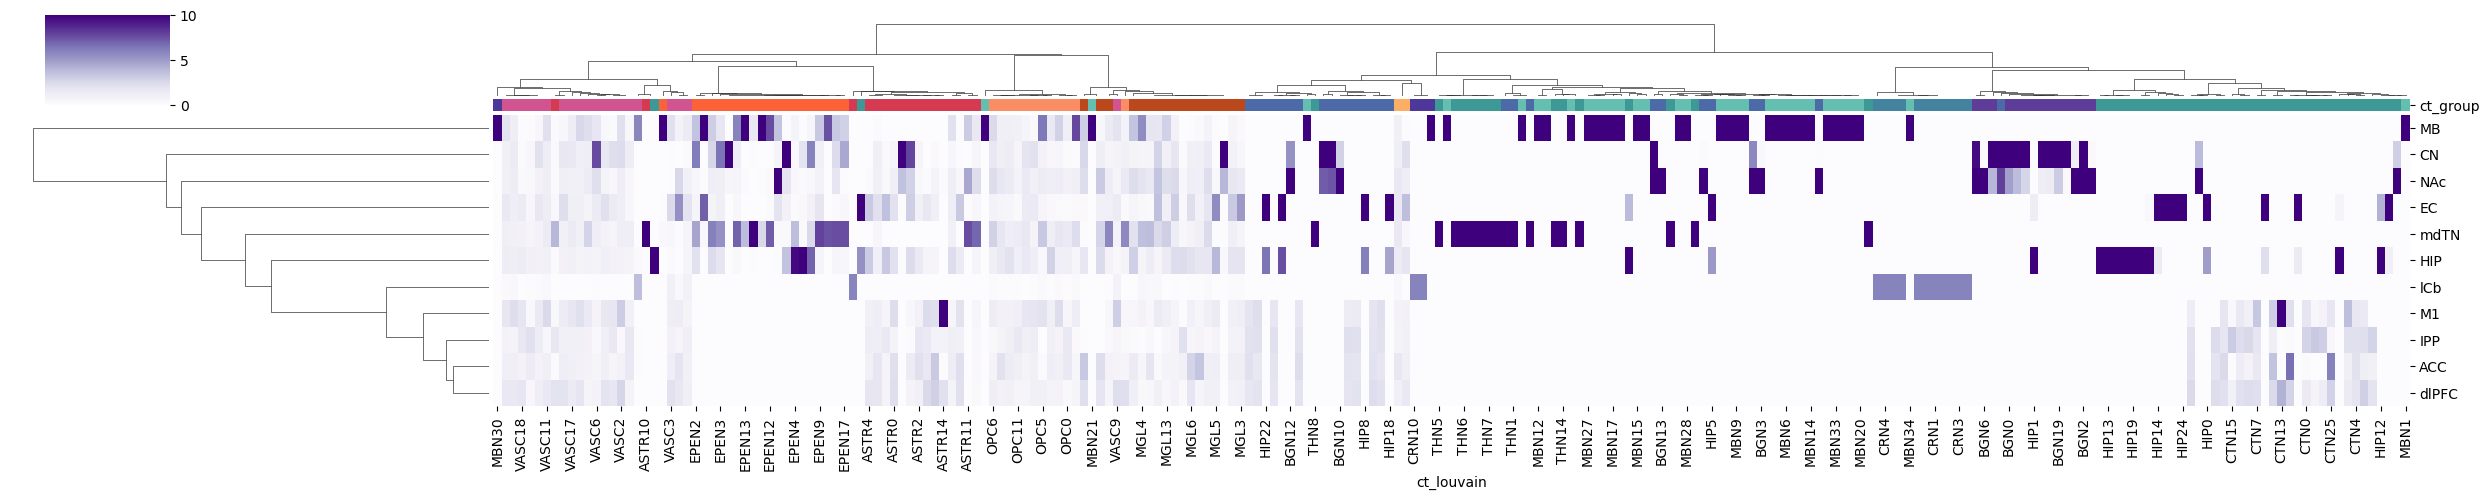

In [24]:
#region distribution
color_map = color_map.set_index('class')
pb_meta = pd.DataFrame(adata_all.obs.groupby('ct_louvain').size().rename('NCells')).reset_index()
temp = pd.DataFrame(adata_all.obs.groupby(['ct_louvain','cell_class_annotation']).size().unstack())

ct_group = temp.idxmax(axis=1)
pb_meta.index =pb_meta['ct_louvain'].astype('str')
pb_meta['ct_group']=ct_group  #ct_group is defined to be the majority cell class but later it should be the cell class
row_linkage = adata_all.uns['dendrogram_ct_louvain']['linkage']
ct_ordering = adata_all.uns['dendrogram_ct_louvain']['categories_ordered']
df = pb_meta.copy()
df.index=df['ct_louvain']

#add region information
region_df = adata_all.obs.groupby(['ct_louvain','region']).size().reset_index(name='count')
a = region_df.groupby('ct_louvain')['count'].transform('sum')
region_df['count'] = region_df['count'].div(a)
region_mat = region_df.pivot_table(index='ct_louvain', columns='region', values='count')
region_sum = adata_all.obs['region'].value_counts(normalize=True)
region_mat = region_mat.div(region_sum[region_mat.columns],axis=1)
df = df.join(region_mat)

ct_group = df.pop('ct_group')
lut = color_map.loc[color_map.index.isin(pb_meta['ct_group'].unique()),].to_dict()
row_colors = ct_group.map(lut['color'])
g = sns.clustermap(df.drop(columns=['ct_louvain','NCells']).T, col_colors=row_colors, row_cluster=True,
                   col_linkage = row_linkage,figsize=(25,5),cmap="Purples",vmax=10)
g.savefig('figures/fig1f_region_distribution_heatmap.pdf',bbox_inches='tight')

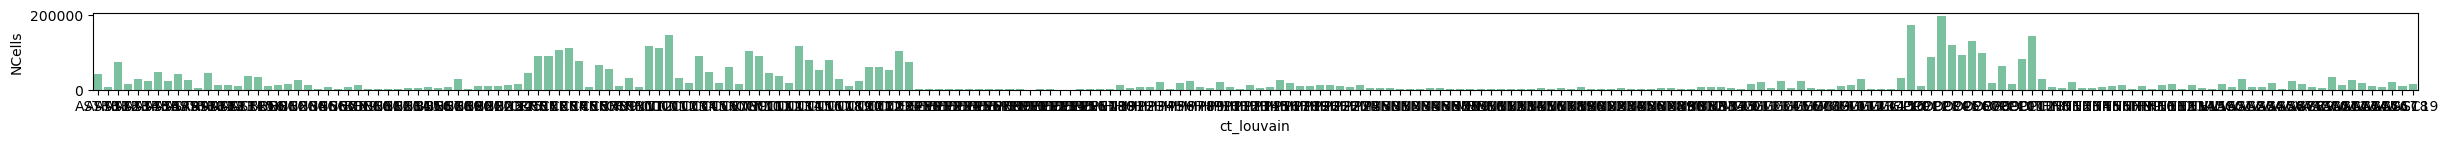

In [56]:
#NCells
data = pb_meta.loc[ct_ordering,]
fig,ax=plt.subplots(1,1,figsize=(30,1))
data['log2NCells']=np.log2(data['NCells'])
sns.barplot(data,x='ct_louvain',y='NCells',ax=ax,color='#6fcb9f')
plt.savefig('figures/fig1f_NCells.pdf',bbox_inches='tight')

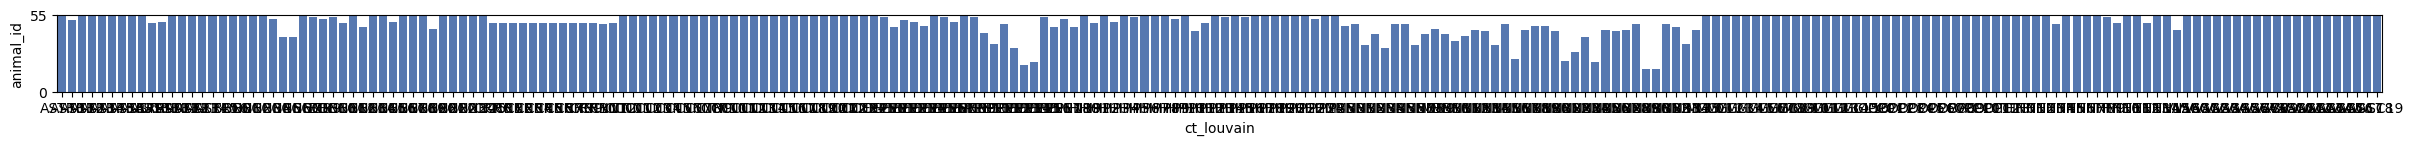

In [57]:
#NCells
pb_animal = pd.DataFrame(adata_all.obs.groupby(['ct_louvain','animal_id']).size().rename('NCells')).reset_index()
data = pb_animal.loc[pb_animal['NCells']>0,].groupby('ct_louvain')['animal_id'].size()
fig,ax=plt.subplots(1,1,figsize=(30,1))
sns.barplot(pd.DataFrame(data),x='ct_louvain',y='animal_id',ax=ax,color='#4874bf')
ax.set_ylim([0,55])
ax.set_yticks([0,55])
plt.savefig('figures/fig1f_Nanimals.pdf',bbox_inches='tight')